<a href="https://colab.research.google.com/github/shahrukhmalik95/victoria/blob/main/Muhammad_Malik_STAT_7110_HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework 1 - Phase I & II Analysis Using Shewhart $\bar{X}$ and R/s Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: September 19, 2026 via D2L**

## Instructions:

A company called Blue Ridge Filament Co (BRFC) manufactures 1.75 mm PLA filament for 3D printers, selling to both hobbyist and small-manufacturing customers. Over the last quarter, customer support tickets describing clogging, stringing, and inconsistent print layers have risen sharply, and BRFC recently lost a wholesale account to a competitor over “inconsistent quality.” The plant manager has asked your quality control team to investigate Extruder Line 3, the line most frequently named in the complaint data, and to determine whether the line is running in a state of statistical control. This line is about six months away from needing its heating element replaced, but it could be replaced sooner if necessary.

The plant manager is particularly interested in the filament diameter produced (mm), measured inline by a laser micrometer as each spool is produced. Diameter that runs too thin causes under-extrusion and stringing; diameter that runs too thick causes jams and clogs in customers' print heads. Filament diameter is treated as a continuous, normally-distributed quality characteristic for this assignment.

Your team pulls a baseline (Phase I) sample of production data from Line 3: 5 spools sampled at random each week, for 25 consecutive weeks. After validating statistical control and process capability, the team can establish an ongoing monitoring plan for Phase II analysis.

## Key Specifications

| Quantity | Value |
|---|---|
| Target diameter | 1.750 mm |
| Lower Specification Limit (LSL) | 1.700 mm |
| Upper Specification Limit (USL) | 1.800 mm |
| Subgroup size (n) | 5 spools per week |
| Phase I subgroups (m) | 25 weeks |
| Phase II subgroups | 20 weeks |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this analysis is to determine whether Extruder Line 3 is producing filament diameter consistently and within the required specifications. The analysis will evaluate whether the process is statistically in control, assess its capability to meet the 1.700–1.800 mm specification limits, and support decisions about future monitoring and possible equipment maintenance.


### Q2: Identify the quality characteristic your team will monitor, classify its units and measurement scale.

The quality characteristic is filament diameter. It is measured in millimeters (mm) and is a continuous, ratio-scale variable.


### Q3: Briefly describe why a Shewhart $\bar{X}$ and $R/s$ chart would be appropriate in this scenario. What are its limitations?

A Shewhart $\bar{X}$ and $R/s$ chart is appropriate because filament diameter is continuous data collected in subgroups. The $\bar{X}$ chart monitors changes in the average diameter, while the $R/s$ chart monitors changes in process variability. Together, they help determine whether the process is statistically stable. One limitation is that Shewhart charts may not detect small or gradual changes in the process quickly. Also, statistical control does not necessarily mean that the process meets the specification limits.




## Analyze

### Q4: Read the Phase I data into R. Calculate and report the estimated process mean and standard deviation using both the $R$ and $s$ methods.

In [ ]:
print("The correct path for 'FilamentDiameter_PhaseI.xlsx' is /content/sample_data/FilamentDiameter_PhaseI.xlsx")

[1] "The correct path for 'FilamentDiameter_PhaseI.xlsx' is /content/sample_data/FilamentDiameter_PhaseI.xlsx"


In [ ]:
## Q4 Code ##
library(readxl)

data <- read_excel("/content/sample_data/FilamentDiameter_PhaseI.xlsx")


measurements <- data[, 2:6]

# Process mean
process_mean <- mean(as.matrix(measurements))

# R method
R_values <- apply(measurements, 1, function(x) max(x) - min(x))
R_bar <- mean(R_values)
sigma_R <- R_bar / 2.326

# s method
s_values <- apply(measurements, 1, sd)
s_bar <- mean(s_values)
c4 <- 0.93999
sigma_s <- s_bar / c4

process_mean
sigma_R
sigma_s

[1] 1.754017

[1] 0.01144864

[1] 0.0115448

The estimated process mean is 1.75 mm. The estimated process standard deviation using the R method is 0.011 mm, while the estimated standard deviation using the s method is 0.011 mm.


### Q5: Construct a Phase I $R$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.

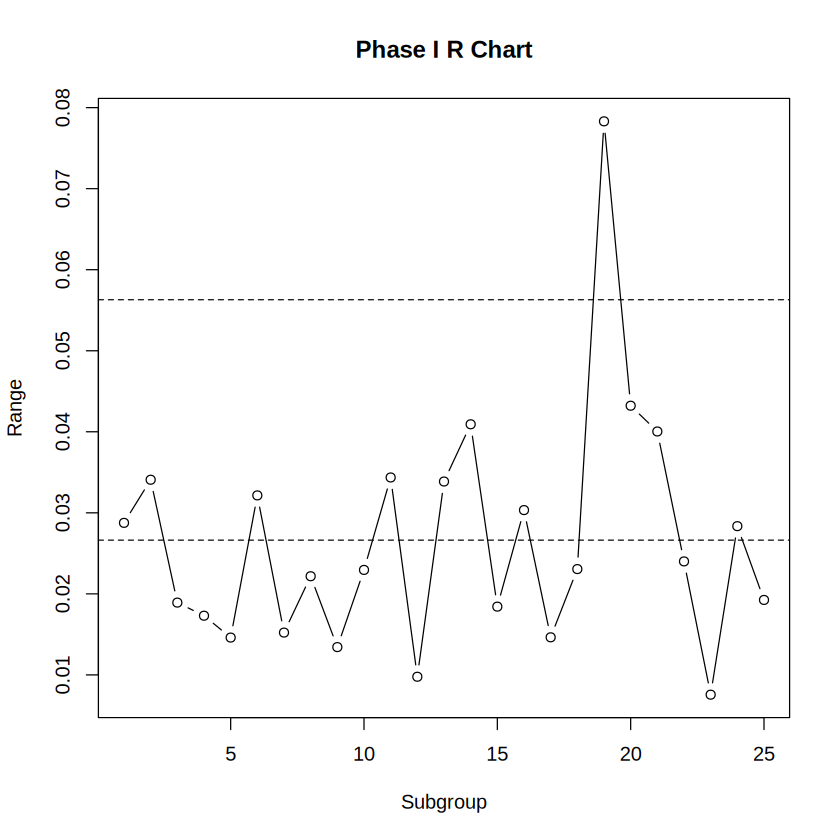

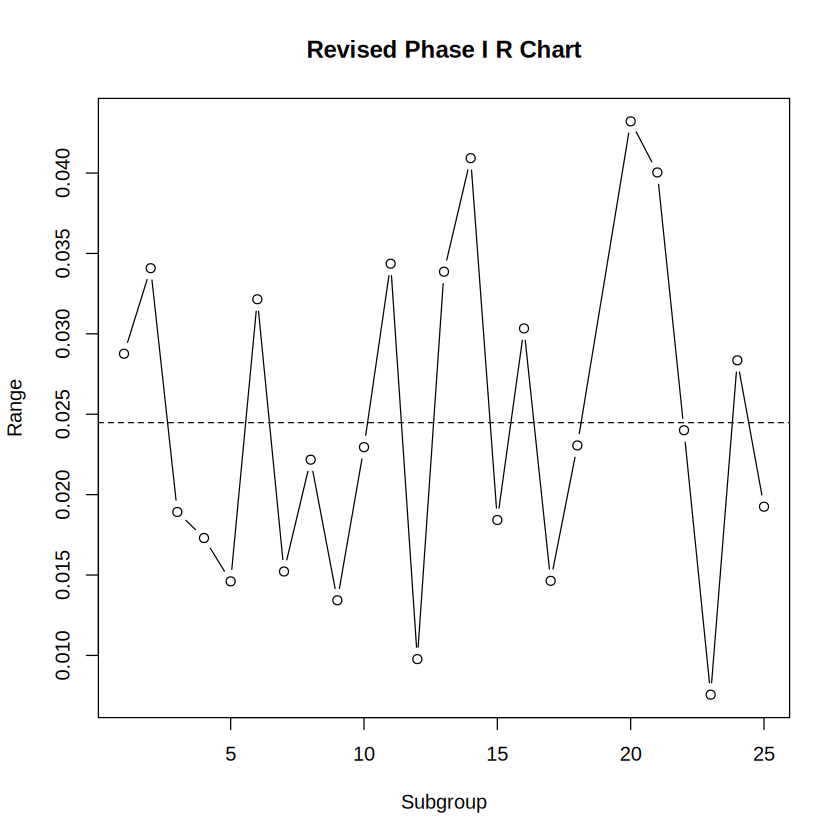

In [ ]:


measurements <- data[, 2:6]
R_values <- apply(measurements, 1, function(x) max(x) - min(x))
R_bar <- mean(R_values)
D3 <- 0
D4 <- 2.114

UCL_R <- D4 * R_bar
LCL_R <- D3 * R_bar

plot(data$Subgroup, R_values,
     type = "b",
     xlab = "Subgroup",
     ylab = "Range",
     main = "Phase I R Chart")

abline(h = R_bar, lty = 2)
abline(h = UCL_R, lty = 2)
abline(h = LCL_R, lty = 2)
data2 <- data[data$Subgroup != 19, ]

measurements2 <- data2[, 2:6]

R_values2 <- apply(measurements2, 1,
                   function(x) max(x) - min(x))

R_bar2 <- mean(R_values2)
UCL_R2 <- D4 * R_bar2
LCL_R2 <- D3 * R_bar2
plot(data2$Subgroup, R_values2,
     type = "b",
     xlab = "Subgroup",
     ylab = "Range",
     main = "Revised Phase I R Chart")

abline(h = R_bar2, lty = 2)
abline(h = UCL_R2, lty = 2)
abline(h = LCL_R2, lty = 2)

In [ ]:

D3 <- 0
D4 <- 2.114


Rbar <- mean(phase1$Range)
UCL_R <- D4 * Rbar
LCL_R <- D3 * Rbar


cat("R-bar =", Rbar, "\n")
cat("UCL =", UCL_R, "\n")
cat("LCL =", LCL_R, "\n")


OOC_R <- phase1$Subgroup[
  phase1$Range > UCL_R | phase1$Range < LCL_R
]

cat("Out-of-control subgroup(s):", OOC_R, "\n")



R-bar = 0.02662954 
UCL = 0.05629484 
LCL = 0 
Out-of-control subgroup(s): 19 


Subgroup 19 may reflect a special cause of variation, which could have caused unusually inconsistent filament diameters during that week.

In [ ]:

phase1_R2 <- phase1[phase1$Subgroup != 19, ]
Rbar2 <- mean(phase1_R2$Range)
UCL_R2 <- D4 * Rbar2
LCL_R2 <- D3 * Rbar2
OOC_R2 <- phase1_R2$Subgroup[
  phase1_R2$Range > UCL_R2 | phase1_R2$Range < LCL_R2
]


cat("Revised R-bar =", Rbar2, "\n")
cat("Revised UCL =", UCL_R2, "\n")
cat("Revised LCL =", LCL_R2, "\n")




Revised R-bar = 0.0244762 
Revised UCL = 0.05174269 
Revised LCL = 0 


The initial Phase I R chart was not in statistical control because Subgroup 19 was above the upper control limit. Subgroup 19 may reflect a special cause of variation, which could have caused unusually inconsistent filament diameters during that week. After removing Subgroup 19 and recalculating the control limits, no additional out-of-control points were observed. Therefore, the revised R chart shows statistical control.

### Q6: Using only the subgroups retained after Q5, construct the Phase I $\bar{X}$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.

X-double-bar = 1.753618 
UCL = 1.767741 
LCL = 1.739496 
Out-of-control subgroup(s): 12 


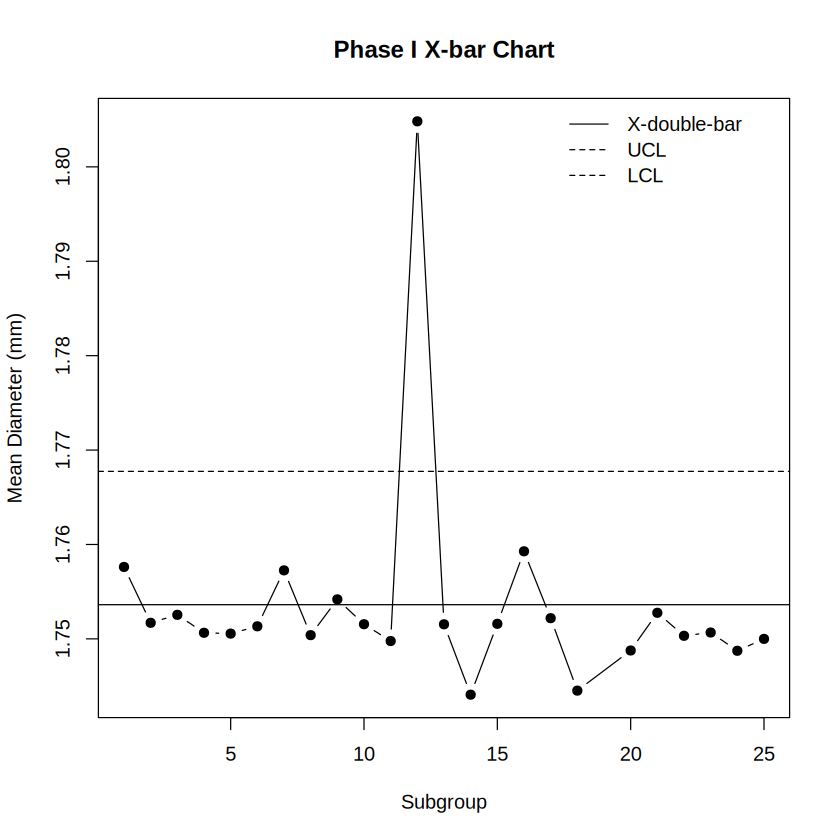

In [ ]:
## Q6 Code ##
A2 <- 0.577
Xbarbar <- mean(phase1_R2$Mean)
Rbar <- mean(phase1_R2$Range)
UCL_X <- Xbarbar + A2 * Rbar
LCL_X <- Xbarbar - A2 * Rbar
OOC_X <- phase1_R2$Subgroup[
  phase1_R2$Mean > UCL_X | phase1_R2$Mean < LCL_X
]


cat("X-double-bar =", Xbarbar, "\n")
cat("UCL =", UCL_X, "\n")
cat("LCL =", LCL_X, "\n")
cat("Out-of-control subgroup(s):", OOC_X, "\n")

plot(
  phase1_R2$Subgroup,
  phase1_R2$Mean,
  type = "b",
  pch = 19,
  xlab = "Subgroup",
  ylab = "Mean Diameter (mm)",
  main = "Phase I X-bar Chart"
)

abline(h = Xbarbar, lty = 1)
abline(h = UCL_X, lty = 2)
abline(h = LCL_X, lty = 2)

legend(
  "topright",
  legend = c("X-double-bar", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)

Subgroup 12 may reflect a special cause of variation that caused the average filament diameter to be unusually high during that week

Revised X-double-bar = 1.751392 
Revised UCL = 1.765884 
Revised LCL = 1.7369 
Remaining out-of-control subgroup(s):  


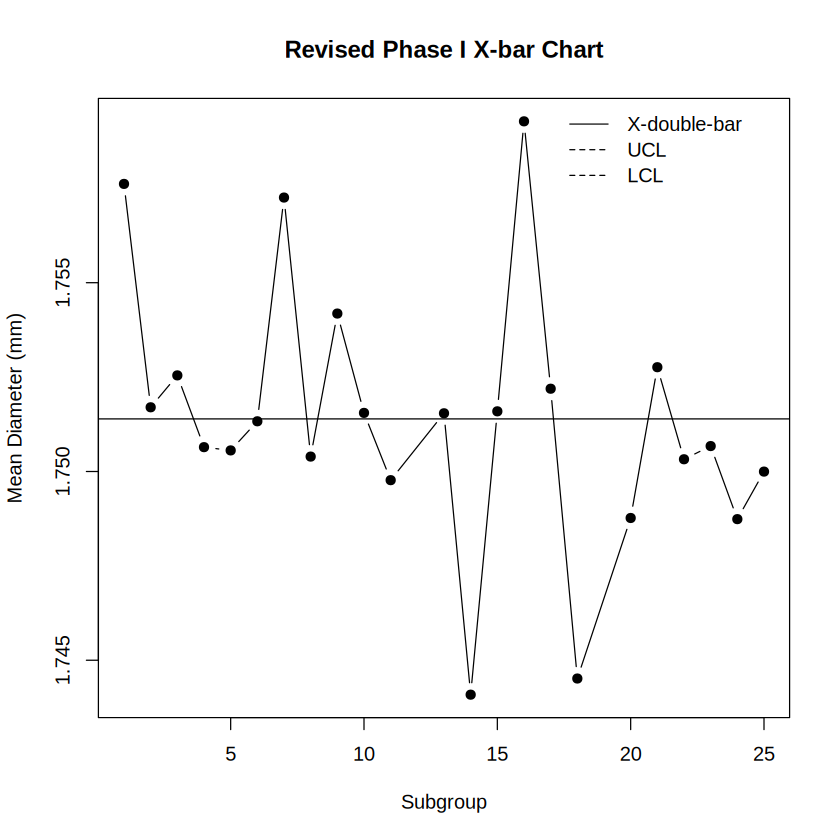

In [ ]:

phase1_X2 <- phase1_R2[phase1_R2$Subgroup != 12, ]
Xbarbar2 <- mean(phase1_X2$Mean)
Rbar_X2 <- mean(phase1_X2$Range)

UCL_X2 <- Xbarbar2 + A2 * Rbar_X2
LCL_X2 <- Xbarbar2 - A2 * Rbar_X2

OOC_X2 <- phase1_X2$Subgroup[
  phase1_X2$Mean > UCL_X2 | phase1_X2$Mean < LCL_X2
]

cat("Revised X-double-bar =", Xbarbar2, "\n")
cat("Revised UCL =", UCL_X2, "\n")
cat("Revised LCL =", LCL_X2, "\n")
cat("Remaining out-of-control subgroup(s):", OOC_X2, "\n")

# Replot revised X-bar chart
plot(
  phase1_X2$Subgroup,
  phase1_X2$Mean,
  type = "b",
  pch = 19,
  xlab = "Subgroup",
  ylab = "Mean Diameter (mm)",
  main = "Revised Phase I X-bar Chart"
)

abline(h = Xbarbar2, lty = 1)
abline(h = UCL_X2, lty = 2)
abline(h = LCL_X2, lty = 2)

legend(
  "topright",
  legend = c("X-double-bar", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)

The initial Phase I $\bar{X}$ chart was not in statistical control because Subgroup 12 was above the upper control limit. This suggests that a special cause may have caused the average filament diameter to be unusually high during that week, possibly due to temporary process or temperature instability. After removing Subgroup 12 and recalculating the control limits, no additional out-of-control points were observed. Therefore, the revised $\bar{X}$ chart is in statistical control.

### Q7: Repeat the same process in Q4 - Q6 now using the $s$ chart instead of the $R$ chart

S-bar = 0.01085199 
UCL = 0.02266981 
LCL = 0 
Out-of-control subgroup(s): 19 


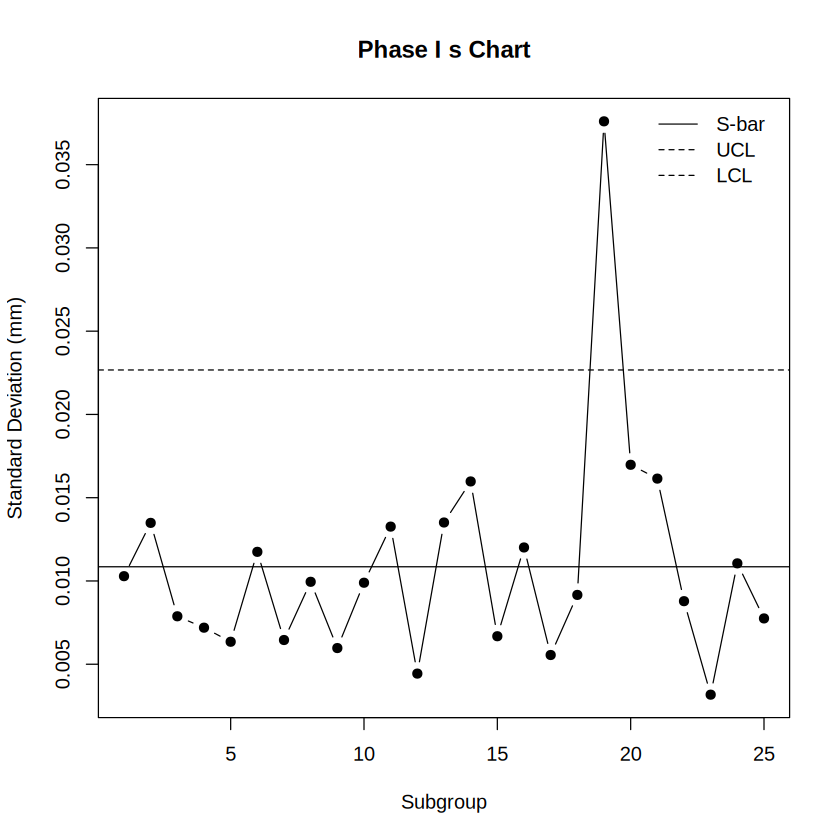

In [ ]:
## Q7 Code ##


B3 <- 0
B4 <- 2.089

phase1$SD <- apply(phase1[, 2:6], 1, sd)
Sbar <- mean(phase1$SD)
UCL_S <- B4 * Sbar
LCL_S <- B3 * Sbar
OOC_S <- phase1$Subgroup[
  phase1$SD > UCL_S | phase1$SD < LCL_S
]

# Display results
cat("S-bar =", Sbar, "\n")
cat("UCL =", UCL_S, "\n")
cat("LCL =", LCL_S, "\n")
cat("Out-of-control subgroup(s):", OOC_S, "\n")

# Construct s chart
plot(
  phase1$Subgroup,
  phase1$SD,
  type = "b",
  pch = 19,
  xlab = "Subgroup",
  ylab = "Standard Deviation (mm)",
  main = "Phase I s Chart"
)

abline(h = Sbar, lty = 1)
abline(h = UCL_S, lty = 2)
abline(h = LCL_S, lty = 2)

legend(
  "topright",
  legend = c("S-bar", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)


Subgroup 19 may reflect a special cause of variation, which could have caused unusually inconsistent filament diameters during that week.

Revised S-bar = 0.009737409 
Revised UCL = 0.02034145 
Revised LCL = 0 


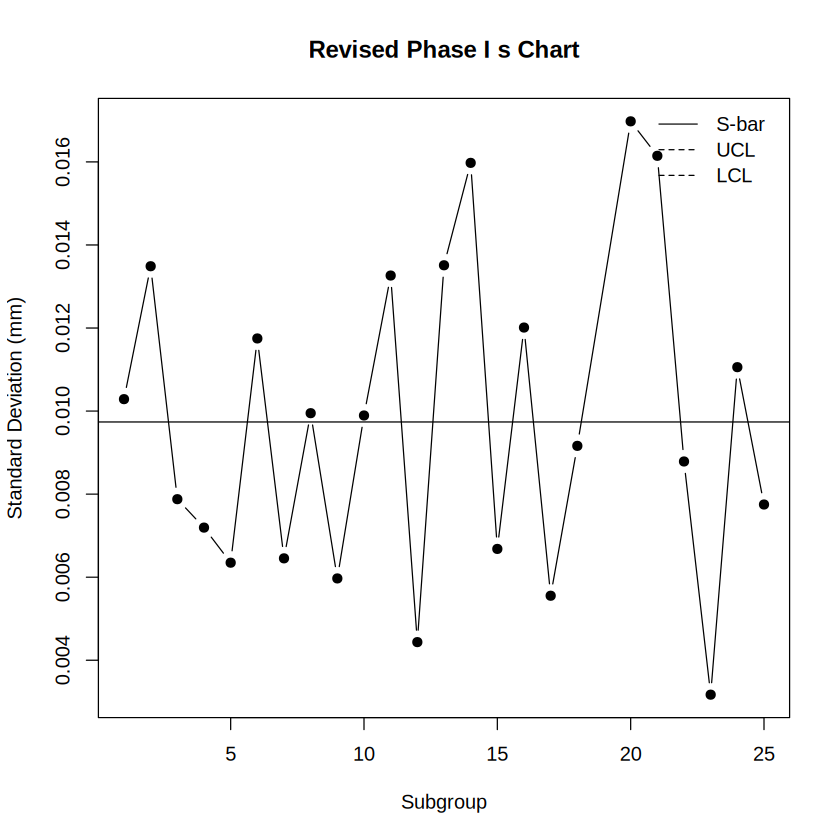

In [ ]:

phase1 <- read_excel("/content/sample_data/FilamentDiameter_PhaseI.xlsx")

phase1$Mean <- rowMeans(phase1[, 2:6])
phase1$Range <- apply(phase1[, 2:6], 1, function(x) max(x) - min(x))
phase1$SD <- apply(phase1[, 2:6], 1, sd)

B3 <- 0
B4 <- 2.089
phase1_S2 <- phase1[phase1$Subgroup != 19, ]
Sbar2 <- mean(phase1_S2$SD)
UCL_S2 <- B4 * Sbar2
LCL_S2 <- B3 * Sbar2
OOC_S2 <- phase1_S2$Subgroup[
  phase1_S2$SD > UCL_S2 | phase1_S2$SD < LCL_S2
]

# Display results
cat("Revised S-bar =", Sbar2, "\n")
cat("Revised UCL =", UCL_S2, "\n")
cat("Revised LCL =", LCL_S2, "\n")

# Revised s chart
plot(
  phase1_S2$Subgroup,
  phase1_S2$SD,
  type = "b",
  pch = 19,
  xlab = "Subgroup",
  ylab = "Standard Deviation (mm)",
  main = "Revised Phase I s Chart"
)

abline(h = Sbar2, lty = 1)
abline(h = UCL_S2, lty = 2)
abline(h = LCL_S2, lty = 2)

legend(
  "topright",
  legend = c("S-bar", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)

X-double-bar = 1.753618 
UCL = 1.767514 
LCL = 1.739723 
Out-of-control subgroup(s): 12 


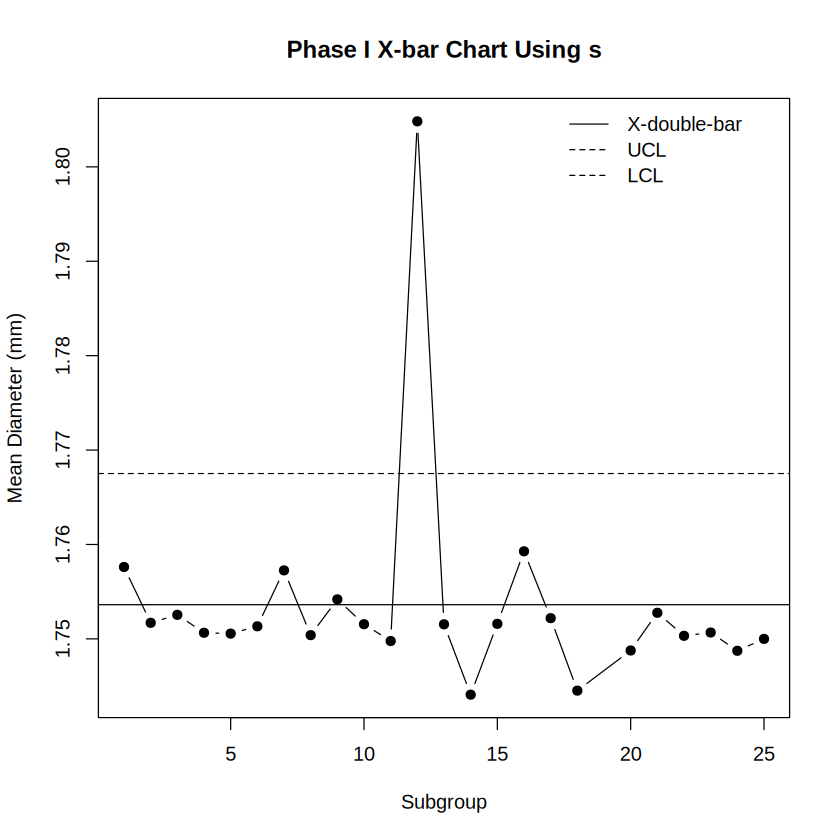

In [ ]:
# Q7: Phase I X-bar Chart using s method

A3 <- 1.427
Xbarbar_S <- mean(phase1_S2$Mean)
Sbar_X <- mean(phase1_S2$SD)
UCL_XS <- Xbarbar_S + A3 * Sbar_X
LCL_XS <- Xbarbar_S - A3 * Sbar_X
OOC_XS <- phase1_S2$Subgroup[
  phase1_S2$Mean > UCL_XS | phase1_S2$Mean < LCL_XS
]

# Display results
cat("X-double-bar =", Xbarbar_S, "\n")
cat("UCL =", UCL_XS, "\n")
cat("LCL =", LCL_XS, "\n")
cat("Out-of-control subgroup(s):", OOC_XS, "\n")

# Construct X-bar chart
plot(
  phase1_S2$Subgroup,
  phase1_S2$Mean,
  type = "b",
  pch = 19,
  xlab = "Subgroup",
  ylab = "Mean Diameter (mm)",
  main = "Phase I X-bar Chart Using s"
)

abline(h = Xbarbar_S, lty = 1)
abline(h = UCL_XS, lty = 2)
abline(h = LCL_XS, lty = 2)

legend(
  "topright",
  legend = c("X-double-bar", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)

Subgroup 12 may reflect a special cause of variation that caused the average filament diameter to be unusually high during that week.

Revised X-double-bar = 1.751392 
Revised UCL = 1.765616 
Revised LCL = 1.737168 
Remaining out-of-control subgroup(s):  


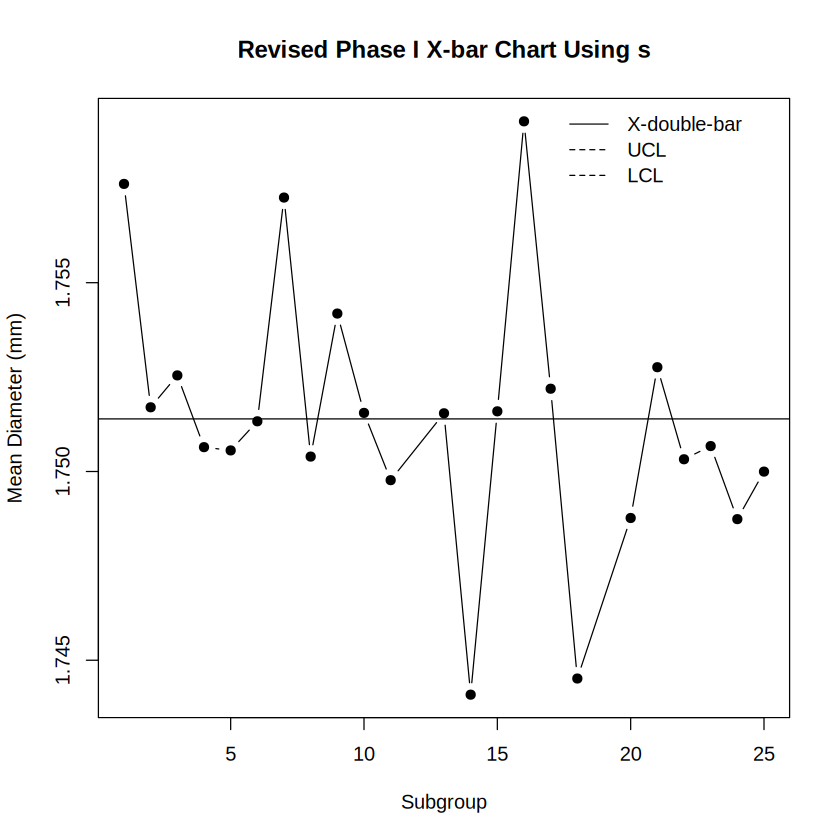

In [ ]:
# Remove out-of-control subgroup 12
phase1_SX2 <- phase1_S2[phase1_S2$Subgroup != 12, ]
Xbarbar_S2 <- mean(phase1_SX2$Mean)
Sbar_X2 <- mean(phase1_SX2$SD)
UCL_XS2 <- Xbarbar_S2 + A3 * Sbar_X2
LCL_XS2 <- Xbarbar_S2 - A3 * Sbar_X2
OOC_XS2 <- phase1_SX2$Subgroup[
  phase1_SX2$Mean > UCL_XS2 | phase1_SX2$Mean < LCL_XS2
]

# Display results
cat("Revised X-double-bar =", Xbarbar_S2, "\n")
cat("Revised UCL =", UCL_XS2, "\n")
cat("Revised LCL =", LCL_XS2, "\n")
cat("Remaining out-of-control subgroup(s):", OOC_XS2, "\n")

# Replot revised X-bar chart
plot(
  phase1_SX2$Subgroup,
  phase1_SX2$Mean,
  type = "b",
  pch = 19,
  xlab = "Subgroup",
  ylab = "Mean Diameter (mm)",
  main = "Revised Phase I X-bar Chart Using s"
)

abline(h = Xbarbar_S2, lty = 1)
abline(h = UCL_XS2, lty = 2)
abline(h = LCL_XS2, lty = 2)

legend(
  "topright",
  legend = c("X-double-bar", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)

After removing Subgroups 19 and 12, the revised $s$ and $\bar{X}$ charts showed statistical control.

### Q8: Using your final Phase I estimates of the process mean and process standard deviation (using $s$ method), perform a process capability analysis against the specification limits given about. Report and interpret $FNC$, $C_p$, $C_{pk}$, and $C_{pm}$. Is the process capable of meeting specification? Is it well-centered?

In [ ]:

LSL <- 1.700
USL <- 1.800
Target <- 1.750

c4 <- 0.9400
mu_hat <- mean(phase1_SX2$Mean)
Sbar_final <- mean(phase1_SX2$SD)
sigma_hat <- Sbar_final / c4
FNC_lower <- pnorm(
  LSL,
  mean = mu_hat,
  sd = sigma_hat
)

FNC_upper <- 1 - pnorm(
  USL,
  mean = mu_hat,
  sd = sigma_hat
)

FNC <- FNC_lower + FNC_upper

# Process Capability Cp
Cp <- (USL - LSL) / (6 * sigma_hat)

# Process Capability Cpk
Cpk <- min(
  (USL - mu_hat) / (3 * sigma_hat),
  (mu_hat - LSL) / (3 * sigma_hat)
)

# Process Capability Cpm
Cpm <- (USL - LSL) /
  (6 * sqrt(
    sigma_hat^2 +
    (mu_hat - Target)^2
  ))

# Display results
cat("Final Process Mean =", mu_hat, "mm\n")
cat("Final Process SD =", sigma_hat, "mm\n")
cat("FNC =", FNC, "\n")
cat("FNC Percentage =", FNC * 100, "%\n")
cat("Cp =", Cp, "\n")
cat("Cpk =", Cpk, "\n")
cat("Cpm =", Cpm, "\n")

Final Process Mean = 1.751392 mm
Final Process SD = 0.01060412 mm
FNC = 2.91073e-06 
FNC Percentage = 0.000291073 %
Cp = 1.571716 
Cpk = 1.527958 
Cpm = 1.558346 


The final estimated process mean is 1.75139 mm, and the estimated process standard deviation using the s method is 0.01060 mm.

The fraction nonconforming (FNC) is approximately 0.00000291, or 0.000291%, indicating that only a very small proportion of filament is expected to fall outside the specification limits.

The process capability indices are:

Cp = 1.572
Cpk = 1.528
Cpm = 1.558

Since both Cp and Cpk are greater than 1.33, the process is capable of meeting the specification limits. The Cpk value is only slightly lower than Cp, and the estimated process mean of 1.75139 mm is very close to the target of 1.750 mm. Therefore, the process is also reasonably well-centered.

## Improve

### Q9: Briefly provide a contextual explanation as to leaving OOC points in the Phase I calculation of the control limits after identifying an assignable cause is not advisable.

Leaving out-of-control points in the Phase I calculations after identifying an assignable cause can distort the estimated process mean and variability. This may produce control limits that do not accurately represent the process under normal operating conditions. Removing those points allows the control limits to better reflect the process when only common-cause variation is present.



## Control

### Q10: Read in the Phase II data into R. Using the finalized Phase I center line and control limits from Q7, construct the Phase II $\bar{X}$ chart. Do any subgroups plot outside the control limits?

Phase I Center Line = 1.751392 
Phase I UCL = 1.765616 
Phase I LCL = 1.737168 


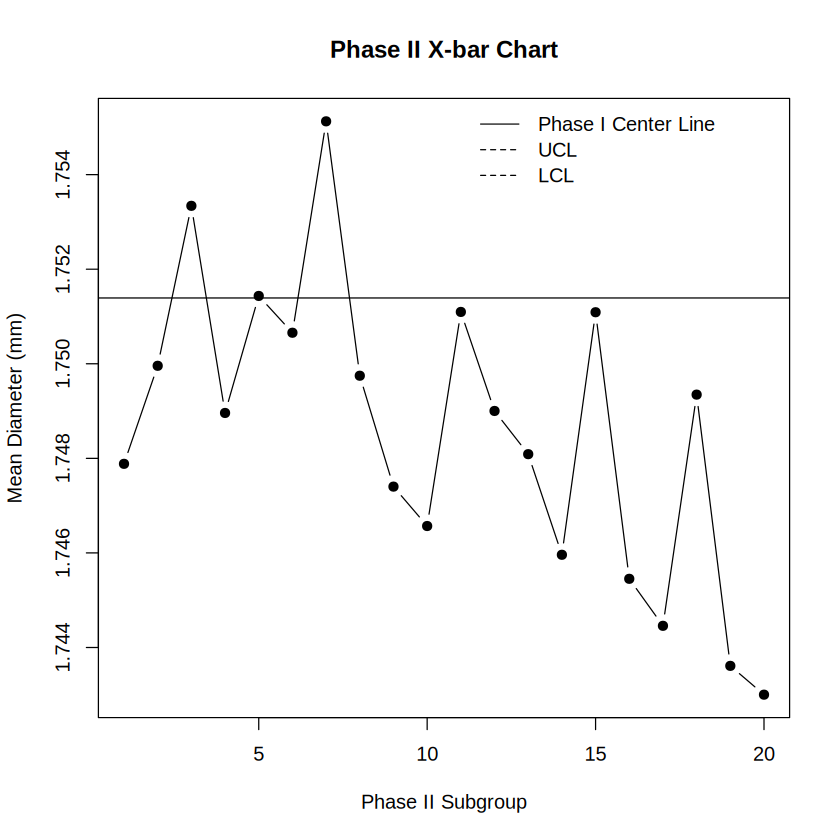

In [ ]:
## Q10 Code ##

library(readxl)

# Phase II data
phase2 <- read_excel("/content//sample_data//FilamentDiameter_PhaseII.xlsx")
phase2$Mean <- rowMeans(phase2[, 2:6])

# Using FINAL Phase I control limits from Q7
CL_Phase1  <- 1.751392
UCL_Phase1 <- 1.765616
LCL_Phase1 <- 1.737168

OOC_Phase2 <- phase2$Subgroup[
  phase2$Mean > UCL_Phase1 | phase2$Mean < LCL_Phase1
]

# Display results
cat("Phase I Center Line =", CL_Phase1, "\n")
cat("Phase I UCL =", UCL_Phase1, "\n")
cat("Phase I LCL =", LCL_Phase1, "\n")

plot(
  phase2$Subgroup,
  phase2$Mean,
  type = "b",
  pch = 19,
  xlab = "Phase II Subgroup",
  ylab = "Mean Diameter (mm)",
  main = "Phase II X-bar Chart"
)

# Add FINAL Phase I limits
abline(h = CL_Phase1, lty = 1)
abline(h = UCL_Phase1, lty = 2)
abline(h = LCL_Phase1, lty = 2)

legend(
  "topright",
  legend = c("Phase I Center Line", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)

No, none of the Phase II subgroups plot outside the finalized Phase I control limits. All 20 subgroup means are within the UCL and LCL.

### Q11: Construct a Phase II $s$ chart. Do any subgroups plot outside the control limits?

Phase I S-bar = 0.009737409 
Phase I UCL = 0.02034145 
Phase I LCL = 0 


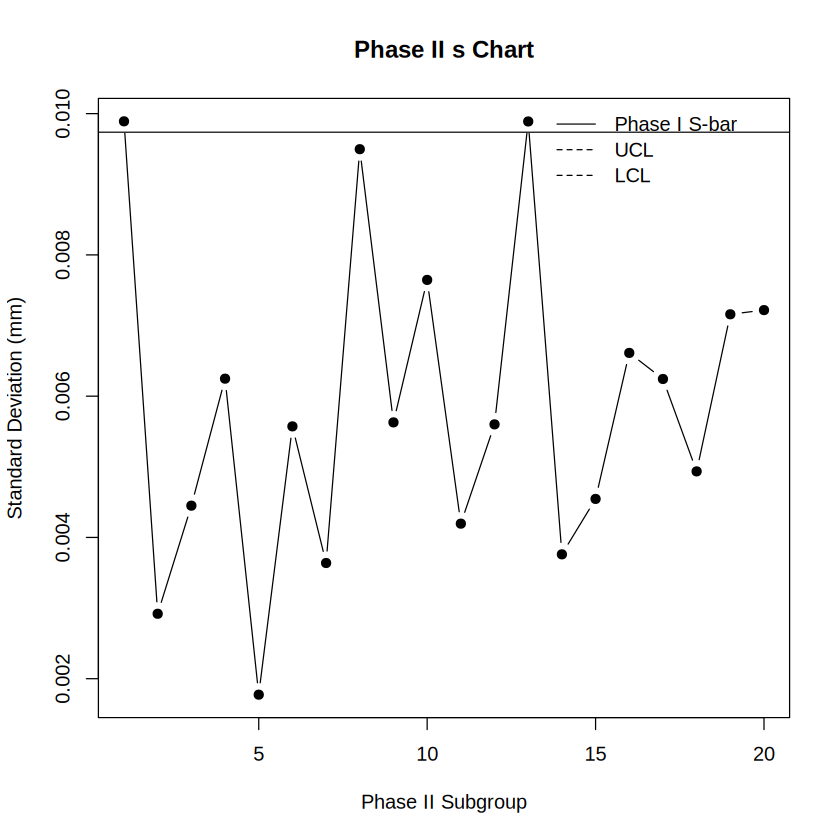

In [ ]:
## Q11 Code ##


phase2$SD <- apply(phase2[, 2:6], 1, sd)
CL_S_Phase1  <- 0.009737409
UCL_S_Phase1 <- 0.02034145
LCL_S_Phase1 <- 0
OOC_S_Phase2 <- phase2$Subgroup[
  phase2$SD > UCL_S_Phase1 | phase2$SD < LCL_S_Phase1
]

# Display results
cat("Phase I S-bar =", CL_S_Phase1, "\n")
cat("Phase I UCL =", UCL_S_Phase1, "\n")
cat("Phase I LCL =", LCL_S_Phase1, "\n")


#  Phase II s chart
plot(
  phase2$Subgroup,
  phase2$SD,
  type = "b",
  pch = 19,
  xlab = "Phase II Subgroup",
  ylab = "Standard Deviation (mm)",
  main = "Phase II s Chart"
)

# Adding finalized Phase I control limits
abline(h = CL_S_Phase1, lty = 1)
abline(h = UCL_S_Phase1, lty = 2)
abline(h = LCL_S_Phase1, lty = 2)

legend(
  "topright",
  legend = c("Phase I S-bar", "UCL", "LCL"),
  lty = c(1, 2, 2),
  bty = "n"
)

No, none of the Phase II subgroups plot outside the finalized Phase I control limits. This indicates that the process variability remains in statistical control during Phase II.

### Q12: Provide an overview of the results that the plant manager can provide the Vice President of Operations. Do they need to completely overhaul line 3 or is it salvagable?

The analysis indicates that Line 3 experienced some unusual variation during Phase I, with Subgroups 19 and 12 identified as out of control. After removing these assignable-cause points and recalculating the control limits, the process became statistically stable and demonstrated good capability to meet the required specification limits. The process mean was also very close to the target diameter, and the expected proportion of nonconforming product was extremely small.

During Phase II monitoring, no subgroups exceeded the control limits on either the $\bar{X}$ or s chart, indicating that the process remained stable. Based on these results, Line 3 appears to be salvageable and does not require a complete overhaul at this time. However, the causes of the Phase I out-of-control points should be investigated, and the line should continue to be monitored closely.